# Tối ưu hóa và so sánh LightGBM — Tuần 8

Mốc là cấu hình LightGBM trong [03_training.ipynb](03_training.ipynb). Dùng lại cách chia theo nhóm tên miền đã lưu ở tuần 4 và nhãn dương **1 = phishing** sau khi ánh xạ từ nhãn UCI. Tập test từng dùng để báo cáo tuần 6. Trong tuần 8, chỉ đo lại tập này sau khi khóa cấu hình; đây là so sánh trên cùng bộ PhiUSIIL và cùng cách chia.

Để chạy lại, mở thư mục dự án trong VS Code, chọn kernel Python 3.12 theo README và chọn **Run All**. Các lượt khớp TF-IDF và huấn luyện có thể mất vài phút.

## 1. Nạp cách chia và xác nhận các nhóm tên miền

In [1]:
from itertools import combinations
from pathlib import Path
import io
import ipaddress
import string
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from lightgbm import LGBMClassifier
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
import tldextract

data_dir = Path("data")
raw = pd.read_csv(data_dir / "PhiUSIIL_Phishing_URL_Dataset.csv", usecols=["URL", "label"],
                  dtype={"URL": "string"}, keep_default_na=False, na_values=[""])
manifest = pd.read_csv(data_dir / "splits.csv", index_col="source_row")
assert raw.shape == (235795, 2) and len(manifest) == 235370
assert manifest.index.is_unique and manifest.index.isin(raw.index).all()
assert set(manifest["split"]) == {"train", "validation", "test"}
data = raw.loc[manifest.index].join(manifest)
assert data["URL"].notna().all() and data["URL"].is_unique
assert set(data["label"]) == {0, 1}

def normalized_host(url):
    host = urlsplit(url).hostname.rstrip(".").lower()
    try:
        return str(ipaddress.ip_address(host))
    except ValueError:
        return host.encode("idna").decode("ascii")

hosts = data["URL"].map(normalized_host)
extract = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)
domains = {host: extract(host) for host in hosts.unique()}
group_by_host = {host: parts.top_domain_under_public_suffix or host for host, parts in domains.items()}
data["domain_group"] = hosts.map(group_by_host)
data["is_phishing"] = data["label"].eq(0).astype(int)
parts = {name: data.loc[data["split"].eq(name)] for name in ("train", "validation", "test")}
for a, b in combinations(parts.values(), 2):
    assert set(a["domain_group"]).isdisjoint(b["domain_group"])

display(data.groupby("split")["is_phishing"].agg(URL="size", phishing="sum"))

,URL,phishing
split,,
test,36229,15744
train,164785,70709
validation,34356,14067


## 2. Hạn chế và hai thử nghiệm

| Hạn chế từ tuần 6 | Thử nghiệm và lý do |
|---|---|
| Trong train, 26,87% URL phishing có đường dẫn khác gốc, so với 0% ở URL hợp lệ. Những mảnh chuỗi gần giao thức và tiền tố máy chủ có gain cao. | Chỉ tạo n-gram từ tên máy chủ chuẩn hóa để kiểm tra độ nhạy khi bỏ đường dẫn, query và giao thức khỏi đầu vào TF-IDF. Giữ 11 đặc trưng số để đo riêng tác động của thay đổi này. Một số đặc trưng số vẫn lấy từ toàn bộ URL. |
| Tuần 6 có 64 URL phishing bị bỏ sót trên test. Cấu hình cây cố định có thể chưa cân bằng tốt giữa việc nhận diện trường hợp hiếm và khả năng tổng quát hóa. | Tìm kiếm lưới nhỏ trên train với các bộ `num_leaves`, `min_child_samples` và `learning_rate` được xác định trước. So sánh hai mức độ phức tạp với mốc, giữ 90 cây và các tham số khác. |

Báo cáo Precision, Recall, F1 và ROC-AUC cho lớp phishing, độ lệch chuẩn mẫu giữa các lượt và thời gian đo trên cùng máy. F1 là tiêu chí chọn chính.

In [2]:
seed = 42
threads = 6
keywords = ("login", "verify", "account", "secure", "update", "password")
punctuation = set(string.punctuation)
numeric_columns = ["url_length", "host_length", "digit_count", "punctuation_count",
                   "dot_count", "hyphen_count", "slash_count", "query_marker_count",
                   "subdomain_count", "is_ip", "keyword_count"]

def host_features(host):
    try:
        ipaddress.ip_address(host)
        return 0, 1
    except ValueError:
        subdomain = domains[host].subdomain
        return (len(subdomain.split(".")) if subdomain else 0), 0

host_metrics = {host: host_features(host) for host in domains}

def lexical_features(frame):
    rows = []
    for url, host in zip(frame["URL"], hosts.loc[frame.index], strict=True):
        subdomains, is_ip = host_metrics[host]
        lower_url = url.lower()
        rows.append((len(url), len(host), sum(ch.isdigit() for ch in url),
                     sum(ch in punctuation for ch in url), url.count("."), url.count("-"),
                     url.count("/"), url.count("?"), subdomains, is_ip,
                     sum(keyword in lower_url for keyword in keywords)))
    return pd.DataFrame(rows, index=frame.index, columns=numeric_columns, dtype=np.float32)

def combine(numeric, ngrams):
    return sparse.hstack([sparse.csr_matrix(numeric), ngrams], format="csr")

def ngram_text(frame, representation):
    return frame["URL"] if representation == "Toàn URL" else hosts.loc[frame.index]

def fit_features(frame, lexical, representation):
    scaler = StandardScaler()
    tfidf = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), lowercase=False,
                           min_df=3, max_features=20_000, dtype=np.float32)
    matrix = combine(scaler.fit_transform(lexical), tfidf.fit_transform(ngram_text(frame, representation)))
    assert int(scaler.n_samples_seen_) == len(frame)
    return matrix, scaler, tfidf

def transform_features(frame, lexical, scaler, tfidf, representation):
    return combine(scaler.transform(lexical), tfidf.transform(ngram_text(frame, representation)))

def evaluate(model, matrix, y):
    pred = model.predict(matrix)
    positive_column = np.flatnonzero(model.classes_ == 1).item()
    prob = model.predict_proba(matrix)[:, positive_column]
    return {
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, prob),
    }, pred, prob

## 3. Tìm kiếm lưới với kiểm định chéo theo nhóm

Dùng ba lượt `StratifiedGroupKFold` với seed 42, cùng thiết lập tuần 6. Mỗi lượt và mỗi cách tạo n-gram có một bộ tiền xử lý khớp riêng trên phần train của lượt đó. Các cấu hình cây trong cùng lượt và cùng biểu diễn dùng lại ma trận đã biến đổi.

Lưới gồm mốc và hai cấu hình mới. Kết quả CV với n-gram toàn URL quyết định bộ tham số tốt nhất trong hai cấu hình mới. Cùng bộ tham số đó được áp dụng khi chỉ thay tham số và khi kết hợp với n-gram máy chủ, để tách đóng góp của từng thay đổi.

In [3]:
from time import perf_counter
from sklearn.model_selection import ParameterGrid

original = {"num_leaves": 31, "min_child_samples": 20, "learning_rate": 0.10}
grid = list(ParameterGrid([
    {"num_leaves": [15], "min_child_samples": [40], "learning_rate": [0.08]},
    {"num_leaves": [47], "min_child_samples": [12], "learning_rate": [0.12]},
]))
parameter_sets = {"Gốc": original, **{f"Lưới {i}": params for i, params in enumerate(grid, 1)}}

def make_model(params):
    return LGBMClassifier(objective="binary", n_estimators=90, colsample_bytree=0.40,
                          max_bin=31, random_state=seed, n_jobs=threads, verbosity=-1,
                          force_col_wise=True, **params)

representations = ["Toàn URL", "Máy chủ"]
metrics_used = ["Precision", "Recall", "F1", "ROC-AUC"]
train = parts["train"]
train_lexical = lexical_features(train)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
cv_rows = []
for fold, (fit_idx, check_idx) in enumerate(
        cv.split(train, train["is_phishing"], groups=train["domain_group"]), 1):
    fit, check = train.iloc[fit_idx], train.iloc[check_idx]
    assert set(fit["domain_group"]).isdisjoint(check["domain_group"])
    assert fit["is_phishing"].nunique() == check["is_phishing"].nunique() == 2
    for representation in representations:
        started = perf_counter()
        X_fit, scaler, tfidf = fit_features(fit, train_lexical.loc[fit.index], representation)
        X_check = transform_features(check, train_lexical.loc[check.index], scaler, tfidf, representation)
        prep_seconds = perf_counter() - started
        for name, params in parameter_sets.items():
            started = perf_counter()
            model = make_model(params).fit(X_fit, fit["is_phishing"])
            fit_seconds = perf_counter() - started
            metrics, _, _ = evaluate(model, X_check, check["is_phishing"])
            cv_rows.append({"N-gram": representation, "Tham số": name, "Lượt": fold,
                            "Tiền xử lý (s)": prep_seconds, "Khớp mô hình (s)": fit_seconds, **metrics})
            print(f"Lượt {fold} · {representation} · {name} · F1 = {metrics['F1']:.4f}", flush=True)

cv_results = pd.DataFrame(cv_rows)
assert len(cv_results) == 3 * len(representations) * len(parameter_sets)
search = (cv_results.groupby(["N-gram", "Tham số"])[metrics_used].agg(["mean", "std"]))
search["Khớp mô hình (s)", "mean"] = cv_results.groupby(["N-gram", "Tham số"])["Khớp mô hình (s)"].mean()
display(pd.DataFrame(parameter_sets).T)
display(search.round(4))

new_candidates = search.loc["Toàn URL"].drop(index="Gốc")
ranking = pd.DataFrame({"F1": new_candidates["F1", "mean"],
                        "Độ lệch F1": new_candidates["F1", "std"],
                        "Tham số": new_candidates.index})
tuned = ranking.rename_axis(None).sort_values(["F1", "Độ lệch F1", "Tham số"], ascending=[False, True, True]).iloc[0]["Tham số"]
print(f"Cấu hình mới tốt nhất theo CV toàn URL: {tuned} · {parameter_sets[tuned]}")

Lượt 1 · Toàn URL · Gốc · F1 = 0.9975
Lượt 1 · Toàn URL · Lưới 1 · F1 = 0.9976
Lượt 1 · Toàn URL · Lưới 2 · F1 = 0.9979
Lượt 1 · Máy chủ · Gốc · F1 = 0.9598
Lượt 1 · Máy chủ · Lưới 1 · F1 = 0.9284
Lượt 1 · Máy chủ · Lưới 2 · F1 = 0.9878
Lượt 2 · Toàn URL · Gốc · F1 = 0.9976
Lượt 2 · Toàn URL · Lưới 1 · F1 = 0.9974
Lượt 2 · Toàn URL · Lưới 2 · F1 = 0.9976
Lượt 2 · Máy chủ · Gốc · F1 = 0.9803
Lượt 2 · Máy chủ · Lưới 1 · F1 = 0.8974
Lượt 2 · Máy chủ · Lưới 2 · F1 = 0.9885
Lượt 3 · Toàn URL · Gốc · F1 = 0.9983
Lượt 3 · Toàn URL · Lưới 1 · F1 = 0.9982
Lượt 3 · Toàn URL · Lưới 2 · F1 = 0.9983
Lượt 3 · Máy chủ · Gốc · F1 = 0.9794
Lượt 3 · Máy chủ · Lưới 1 · F1 = 0.9430
Lượt 3 · Máy chủ · Lưới 2 · F1 = 0.9905
Cấu hình mới tốt nhất theo CV toàn URL: Lưới 2 · {'learning_rate': 0.12, 'min_child_samples': 12, 'num_leaves': 47}


,num_leaves,min_child_samples,learning_rate
Gốc,31.0,20.0,0.10
Lưới 1,15.0,40.0,0.08
Lưới 2,47.0,12.0,0.12


Precision          ...         Khớp mô hình (s)
                      mean     std  ...     std             mean
N-gram   Tham số                    ...                         
Máy chủ  Gốc        0.9944  0.0021  ...  0.0014           9.7762
         Lưới 1     0.9899  0.0016  ...  0.0054           7.5526
         Lưới 2     0.9965  0.0001  ...  0.0002          10.6293
Toàn URL Gốc        1.0000  0.0001  ...  0.0002          13.0344
         Lưới 1     1.0000  0.0001  ...  0.0002          13.3856
         Lưới 2     0.9999  0.0001  ...  0.0003          13.4308

[6 rows x 9 columns]

## 4. So sánh từng thay đổi trên validation

Khớp từng cấu hình trên toàn bộ train. So sánh bốn cấu hình trên cùng validation. Chọn F1 validation cao nhất. Nếu bằng F1, ưu tiên độ lệch chuẩn F1 thấp hơn rồi thời gian khớp trung bình thấp hơn trong CV. Bảng lỗi theo nhóm dùng mốc tuần 6 để kiểm tra lại các nhóm dễ bỏ sót trên validation.

In [4]:
experiment = {
    "Gốc": ("Toàn URL", "Gốc"),
    "Chỉ đổi đặc trưng": ("Máy chủ", "Gốc"),
    "Chỉ chỉnh tham số": ("Toàn URL", tuned),
    "Kết hợp": ("Máy chủ", tuned),
}
validation = parts["validation"]
val_lexical = lexical_features(validation)
y_val = validation["is_phishing"]
validation_rows = []
validation_predictions = {}
fitted = {}
for representation in representations:
    started = perf_counter()
    X_train, scaler, tfidf = fit_features(train, train_lexical, representation)
    X_val = transform_features(validation, val_lexical, scaler, tfidf, representation)
    prep_seconds = perf_counter() - started
    for name, (rep, params_name) in experiment.items():
        if rep != representation:
            continue
        started = perf_counter()
        model = make_model(parameter_sets[params_name]).fit(X_train, train["is_phishing"])
        fit_seconds = perf_counter() - started
        metrics, pred, _ = evaluate(model, X_val, y_val)
        cv_row = search.loc[(rep, params_name)]
        validation_rows.append({
            "Cấu hình": name, "F1 CV": cv_row["F1", "mean"], "Độ lệch F1 CV": cv_row["F1", "std"],
            **metrics, "Khớp CV (s)": cv_row["Khớp mô hình (s)", "mean"],
            "Tiền xử lý (s)": prep_seconds, "Khớp train (s)": fit_seconds,
        })
        validation_predictions[name] = pred
        fitted[name] = (model, scaler, tfidf, rep)
        print(f"Validation · {name} · F1 = {metrics['F1']:.4f}", flush=True)

val_results = pd.DataFrame(validation_rows).set_index("Cấu hình").loc[list(experiment)]
ordered = val_results.reset_index().sort_values(
    ["F1", "Độ lệch F1 CV", "Khớp CV (s)", "Cấu hình"], ascending=[False, True, True, True])
winner_name = ordered.iloc[0]["Cấu hình"]
display(val_results.round(5))

short = val_lexical["url_length"].le(25)
one_subdomain = val_lexical["subdomain_count"].eq(1)
groups = {"URL ≤25 ký tự": short, "URL >25 ký tự": ~short,
          "Có đúng 1 tên miền con": one_subdomain, "Số tên miền con khác 1": ~one_subdomain}
error_rows = []
for name in dict.fromkeys(["Gốc", winner_name]):
    fn = y_val.eq(1) & (validation_predictions[name] == 0)
    for group, mask in groups.items():
        positive = int((mask & y_val.eq(1)).sum())
        missed = int((mask & fn).sum())
        error_rows.append({"Cấu hình": name, "Nhóm": group, "Phishing": positive,
                           "Bỏ sót": missed, "FNR (%)": 100 * missed / positive if positive else np.nan})
display(pd.DataFrame(error_rows).round(3))

baseline_f1 = val_results.loc["Gốc", "F1"]
feature_delta = val_results.loc["Chỉ đổi đặc trưng", "F1"] - baseline_f1
param_delta = val_results.loc["Chỉ chỉnh tham số", "F1"] - baseline_f1
combined_delta = val_results.loc["Kết hợp", "F1"] - baseline_f1
display(Markdown(
    f"- Đổi n-gram sang máy chủ: ΔF1 validation **{feature_delta:+.5f}**.\n"
    f"- Chỉ chỉnh tham số: **{param_delta:+.5f}**. Kết hợp hai thay đổi: **{combined_delta:+.5f}**.\n"
    f"- Chốt **{winner_name}** theo F1 validation **{val_results.loc[winner_name, 'F1']:.5f}**."
))

Validation · Gốc · F1 = 0.9976
Validation · Chỉ chỉnh tham số · F1 = 0.9976
Validation · Chỉ đổi đặc trưng · F1 = 0.9783
Validation · Kết hợp · F1 = 0.9894


,F1 CV,Độ lệch F1 CV,Precision,Recall,F1,ROC-AUC,Khớp CV (s),Tiền xử lý (s),Khớp train (s)
Cấu hình,,,,,,,,,
Gốc,0.99782,0.00043,1.00000,0.99524,0.99761,0.99865,13.03439,12.37290,11.11211
Chỉ đổi đặc trưng,0.97316,0.01154,0.99624,0.96097,0.97829,0.99704,9.77621,7.34372,10.92420
Chỉ chỉnh tham số,0.99794,0.00036,1.00000,0.99531,0.99765,0.99876,13.43081,12.37290,14.21989
Kết hợp,0.98896,0.00141,0.99812,0.98088,0.98942,0.99844,10.62929,7.34372,14.81305


,Cấu hình,Nhóm,Phishing,Bỏ sót,FNR (%)
0,Gốc,URL ≤25 ký tự,3202,19,0.593
1,Gốc,URL >25 ký tự,10865,48,0.442
2,Gốc,Có đúng 1 tên miền con,7172,61,0.851
3,Gốc,Số tên miền con khác 1,6895,6,0.087
4,Chỉ chỉnh tham số,URL ≤25 ký tự,3202,18,0.562
5,Chỉ chỉnh tham số,URL >25 ký tự,10865,48,0.442
6,Chỉ chỉnh tham số,Có đúng 1 tên miền con,7172,60,0.837
7,Chỉ chỉnh tham số,Số tên miền con khác 1,6895,6,0.087


- Đổi n-gram sang máy chủ: ΔF1 validation **-0.01932**.
- Chỉ chỉnh tham số: **+0.00004**. Kết hợp hai thay đổi: **-0.00819**.
- Chốt **Chỉ chỉnh tham số** theo F1 validation **0.99765**.

## 5. Trực quan hóa và giải thích

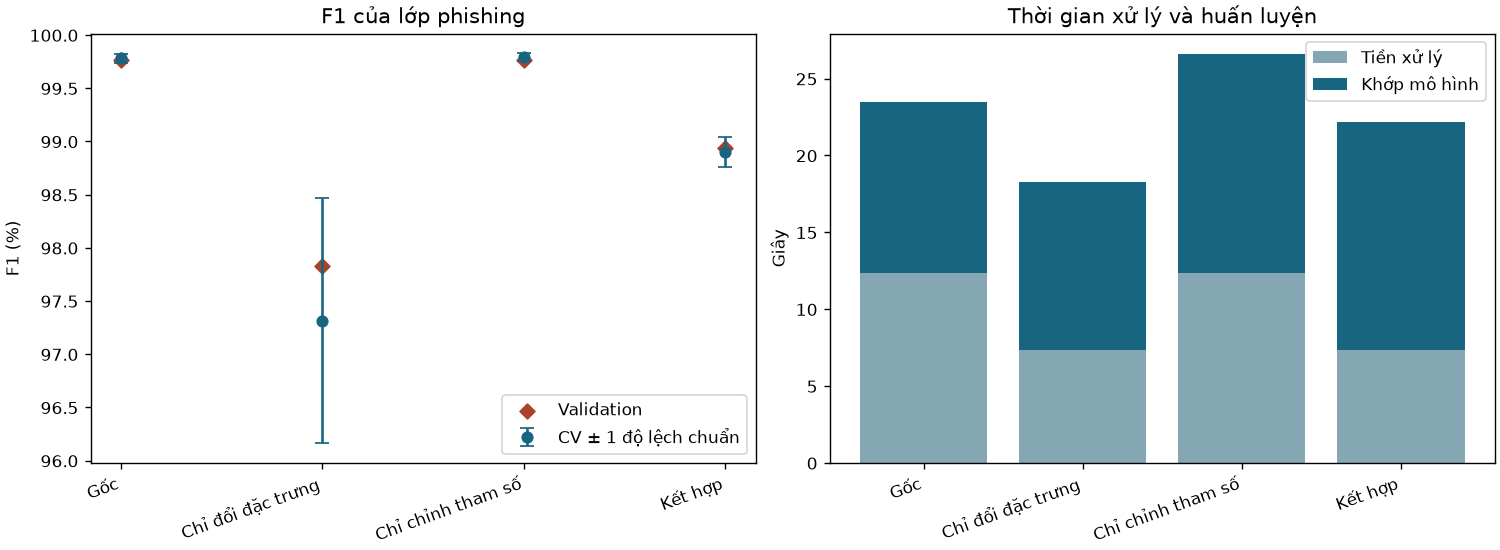

- Biểu đồ F1: cấu hình **Chỉ chỉnh tham số** có F1 validation **0.99765**, F1 CV trung bình **0.99794** và độ lệch chuẩn **0.00036**. Sai số giữa các lượt giúp đọc mức ổn định khi gặp nhóm tên miền khác.
- Biểu đồ thời gian: **Chỉ đổi đặc trưng** có tổng thời gian thấp nhất trong lượt đo này. Thời gian phụ thuộc máy và tải nền, còn phần tiền xử lý được chia sẻ giữa các cấu hình dùng cùng kiểu n-gram.

In [5]:
def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=125)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
positions = np.arange(len(experiment))
axes[0].errorbar(positions, 100 * val_results["F1 CV"], yerr=100 * val_results["Độ lệch F1 CV"],
                 fmt="o", capsize=4, color="#176581", label="CV ± 1 độ lệch chuẩn")
axes[0].scatter(positions, 100 * val_results["F1"], marker="D", color="#aa432b", label="Validation")
axes[0].set(title="F1 của lớp phishing", ylabel="F1 (%)")
axes[0].legend()
axes[1].bar(positions, val_results["Tiền xử lý (s)"], label="Tiền xử lý", color="#85a7b4")
axes[1].bar(positions, val_results["Khớp train (s)"], bottom=val_results["Tiền xử lý (s)"],
            label="Khớp mô hình", color="#176581")
axes[1].set(title="Thời gian xử lý và huấn luyện", ylabel="Giây")
axes[1].legend()
for axis in axes:
    axis.set_xticks(positions, list(experiment), rotation=20, ha="right")
show_figure(fig)

fastest = (val_results["Tiền xử lý (s)"] + val_results["Khớp train (s)"]).idxmin()
winner_row = val_results.loc[winner_name]
display(Markdown(
    f"- Biểu đồ F1: cấu hình **{winner_name}** có F1 validation "
    f"**{winner_row['F1']:.5f}**, F1 CV trung bình **{winner_row['F1 CV']:.5f}** "
    f"và độ lệch chuẩn **{winner_row['Độ lệch F1 CV']:.5f}**. "
    "Sai số giữa các lượt giúp đọc mức ổn định khi gặp nhóm tên miền khác.\n"
    f"- Biểu đồ thời gian: **{fastest}** có tổng thời gian thấp nhất trong lượt đo này. "
    "Thời gian phụ thuộc máy và tải nền, còn phần tiền xử lý được chia sẻ giữa "
    "các cấu hình dùng cùng kiểu n-gram."
))

## 6. Đánh giá cuối trên test

Chỉ dùng tập test sau bước chốt ở trên. Đối chiếu F1 test với F1 CV và validation. Kết quả LightGBM tuần 6 dùng để tham chiếu trên cùng tập test sau khi chốt, không tham gia chọn tham số hoặc cấu hình tuần 8.

In [6]:
test = parts["test"]
model, scaler, tfidf, representation = fitted[winner_name]
X_test = transform_features(test, lexical_features(test), scaler, tfidf, representation)
test_metrics, test_pred, _ = evaluate(model, X_test, test["is_phishing"])
reference = {"Precision": 1.0000, "Recall": 0.9959, "F1": 0.9980, "ROC-AUC": 0.9989}
display(pd.DataFrame([reference, test_metrics], index=["Tuần 6 (đã làm tròn)", f"Tuần 8 · {winner_name}"]).round(5))
cm = confusion_matrix(test["is_phishing"], test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
display(pd.DataFrame(cm, index=["Thực: hợp lệ", "Thực: phishing"],
                     columns=["Dự đoán hợp lệ", "Dự đoán phishing"]))
display(Markdown(
    f"F1 test **{test_metrics['F1']:.5f}**. Chênh lệch so với trung bình CV "
    f"**{test_metrics['F1'] - winner_row['F1 CV']:+.5f}** và so với validation "
    f"**{test_metrics['F1'] - winner_row['F1']:+.5f}**. "
    f"Có **{fn}** URL lừa đảo bị bỏ sót và **{fp}** URL hợp lệ bị cảnh báo nhầm."
))

,Precision,Recall,F1,ROC-AUC
Tuần 6 (đã làm tròn),1.00000,0.99590,0.99800,0.99890
Tuần 8 · Chỉ chỉnh tham số,0.99994,0.99593,0.99793,0.99895


,Dự đoán hợp lệ,Dự đoán phishing
Thực: hợp lệ,20484,1
Thực: phishing,64,15680


F1 test **0.99793**. Chênh lệch so với trung bình CV **-0.00001** và so với validation **+0.00028**. Có **64** URL lừa đảo bị bỏ sót và **1** URL hợp lệ bị cảnh báo nhầm.

**Vấn đáp và thực hành:** thay một giá trị trong lưới rồi chạy phần CV và so sánh F1 trung bình, độ lệch chuẩn và thời gian. Giải thích vì sao giữ cùng lượt chia cho các cấu hình, vì sao tham số phải chọn trước khi đo test và vì sao giữ hoặc bỏ n-gram máy chủ. Gain của cây có thể giúp kiểm tra tín hiệu quan trọng. Cả hai cách biểu diễn vẫn phụ thuộc vào đặc điểm mẫu của PhiUSIIL, nên kết quả trên nguồn URL độc lập vẫn cần được kiểm chứng.